# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Кутельмах Євген'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 8      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 8, файл lr6_варіант_08.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: прогнозуємо значення чи піде клієнт чи ні

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: бо для задач бінарної класифікації AUC краще передає якість моделі

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: бо стратифікація зберігає реальну пропорцію відтоку в кожному блоці, а повтори зменшують вплив випадковості

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.256

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.

summary = pd.DataFrame({
    'тип': raw.dtypes,
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': raw.apply(lambda x: x.dropna().iloc[0] if x.notna().any() else None)
}).reset_index().rename(columns={'index': 'стовпець'})

summary = summary.sort_values('% пропусків', ascending=False).reset_index(drop=True)

pd.set_option('display.max_rows', None)
display(summary)

,стовпець,тип,унікальних,% пропусків,приклад
0,дата_розірвання,str,257,74.4,2025-05-07
1,код_причини_закриття,str,5,74.4,ЯКІ-03
2,середній_час_відповіді_хв,float64,266,32.7,6.9
3,трафік_ГБ,str,946,5.0,48.2
4,щомісячний_платіж,str,1132,4.0,289.03
5,аварій_на_ділянці_за_квартал,float64,7,3.0,1.0
6,стать,str,6,0.0,ж
7,місто,str,6,0.0,Львів
8,id_клієнта,str,1200,0.0,K80000
9,вік,float64,63,0.0,35.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
numeric_columns = [
    'вік',
    'кількість_послуг',
    'місяців_обслуговування',
    'швидкість_тарифу_Мбіт',
    'щомісячний_платіж',
    'знижка_відсоток',
    'трафік_ГБ',
    'кількість_звернень_у_підтримку',
    'аварій_на_ділянці_за_квартал',
    'середній_час_відповіді_хв',
    'річний_платіж'
]

print('1. ЧИСЛОВІ СТОВПЦІ З ТЕКСТОВИМИ ЗНАЧЕННЯМИ')

for col in numeric_columns:
    values = raw[col].dropna()
    invalid = values[pd.to_numeric(values, errors='coerce').isna()]

    if not invalid.empty:
        print(f'\nСтовпець: {col}')
        display(raw.loc[invalid.index, ['id_клієнта', col]].head(5))


print('\n2. ДАТИ В СТОВПЦЯХ, ДЕ ОЧІКУЮТЬСЯ ЧИСЛА')

date_pattern = r'\d{1,4}[-./]\d{1,2}[-./]\d{1,4}'

for col in numeric_columns:
    values = raw[col].dropna().astype(str)
    date_like = values[values.str.contains(date_pattern)]

    if not date_like.empty:
        print(f'\nСтовпець: {col}')
        display(raw.loc[date_like.index, ['id_клієнта', col]].head(5))


print('\n3. MNAR — ПРОПУСКИ В ДАТІ РОЗІРВАННЯ')

col = 'дата_розірвання'

print('\nКлієнти без відтоку, у яких дата розірвання відсутня:')
display(
    raw.loc[
        (raw['відтік'] == 0) & raw[col].isna(),
        ['id_клієнта', 'відтік', col]
    ].head(5)
)

print('\nКлієнти з відтоком, у яких дата розірвання заповнена:')
display(
    raw.loc[
        (raw['відтік'] == 1) & raw[col].notna(),
        ['id_клієнта', 'відтік', col]
    ].head(5)
)

1. ЧИСЛОВІ СТОВПЦІ З ТЕКСТОВИМИ ЗНАЧЕННЯМИ

Стовпець: щомісячний_платіж


,id_клієнта,щомісячний_платіж
15,K80015,347.37 грн
184,K80184,210.38 грн
220,K80220,204.4 грн
263,K80263,399.64 грн
279,K80279,255.66 грн



Стовпець: трафік_ГБ


,id_клієнта,трафік_ГБ
326,K80326,1900-01-19 00:00:00
689,K80689,1900-01-18 00:00:00
860,K80860,1900-01-21 00:00:00



2. ДАТИ В СТОВПЦЯХ, ДЕ ОЧІКУЮТЬСЯ ЧИСЛА

Стовпець: трафік_ГБ


,id_клієнта,трафік_ГБ
326,K80326,1900-01-19 00:00:00
689,K80689,1900-01-18 00:00:00
860,K80860,1900-01-21 00:00:00



3. MNAR — ПРОПУСКИ В ДАТІ РОЗІРВАННЯ

Клієнти без відтоку, у яких дата розірвання відсутня:


,id_клієнта,відтік,дата_розірвання
0,K80000,0,NaN
1,K80001,0,NaN
2,K80002,0,NaN
3,K80003,0,NaN
4,K80004,0,NaN



Клієнти з відтоком, у яких дата розірвання заповнена:


,id_клієнта,відтік,дата_розірвання
17,K80017,1,2025-05-07
20,K80020,1,2025-04-22
23,K80023,1,2024-11-09
25,K80025,1,2024-08-17
27,K80027,1,2024-06-07


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'дата_розірвання'    # назва стовпця
MNAR_MEANING           = 'Що клієнт досі користувається послугами'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if pd.isna(v):
            return np.nan

        if isinstance(v, (datetime.datetime, pd.Timestamp, datetime.date, np.datetime64)):
            return np.nan

        if isinstance(v, (int, float)):
            return float(v)

        v_str = str(v)
        match = re.search(r'-?\d+(?:[.,]\d+)?', v_str)
        if match:
            return float(match.group(0).replace(',', '.'))

        return np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
            
        if c == 'дата_підключення':
            X[c] = pd.to_datetime(d[c], errors='coerce').apply(
                lambda x: x.toordinal() if pd.notnull(x) else np.nan
            )
            log.append({'стовпець': c, 'дія': 'дата -> число (toordinal)'})
            continue

        if pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            log.append({'стовпець': c, 'дія': 'число -> float'})
            continue

        num_series = to_number(d[c])

        valid_count = d[c].notna().sum()
        num_count = num_series.notna().sum()

        if valid_count > 0 and (num_count / valid_count) > 0.8:
            X[c] = num_series
            log.append({'стовпець': c, 'дія': 'текст (>80% чисел) -> число'})
        else:
            def clean_text(x):
                if pd.isna(x):
                    return np.nan
                return str(x).lower().strip()
    
            X[c] = d[c].apply(clean_text).astype('category')
            log.append({'стовпець': c, 'дія': 'текст -> категорія'})

    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 6


,стовпець,дія
0,вік,число -> float
1,стать,текст -> категорія
2,місто,текст -> категорія
3,філія,текст (>80% чисел) -> число
4,тариф,текст -> категорія
5,тип_підключення,текст -> категорія
6,спосіб_оплати,текст -> категорія
7,автоплатіж,текст -> категорія
8,кількість_послуг,число -> float
9,місяців_обслуговування,число -> float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    numeric_features = X.select_dtypes(include=['number']).columns
    categorical_features = X.select_dtypes(include=['category', 'object']).columns
    
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])
    
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.968


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.967 ± 0.011
час      : 0.7 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'Швидше за все у даних є витік, оскільки одержане значення занадто високе (друга ймовірна причина - модель працює майже ідеально)'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

Швидше за все у даних є витік, оскільки одержане значення занадто високе (друга ймовірна причина - модель працює майже ідеально)


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        # ----- ВАШ КОД -----
        notna_mask = d[c].notna()
        n_notna = notna_mask.sum()
        n_isna = (~notna_mask).sum()
        
        mean_notna = y[notna_mask].mean() if n_notna > 0 else np.nan
        mean_isna = y[~notna_mask].mean() if n_isna > 0 else np.nan
        
        if n_notna >= min_group and n_isna >= min_group:
            auc = roc_auc_score(y, notna_mask.astype(int))
            score = max(auc, 1.0 - auc)
        else:
            score = 0.5
            
        rows.append({
            'ознака': c,
            'заповнено': n_notna,
            'частка_відтоку_де_заповнено': mean_notna,
            'частка_відтоку_де_пропуск': mean_isna,
            'показник': score
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,307,1.000000,0.000000,1.000000
23,дата_розірвання,307,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,808,0.279703,0.206633,0.542210
14,трафік_ГБ,1140,0.257018,0.233333,0.502955
16,аварій_на_ділянці_за_квартал,1164,0.255155,0.277778,0.501729
12,щомісячний_платіж,1152,0.256076,0.250000,0.500613
2,стать,1200,0.255833,NaN,0.500000
1,вік,1200,0.255833,NaN,0.500000
0,id_клієнта,1200,0.255833,NaN,0.500000
8,автоплатіж,1200,0.255833,NaN,0.500000


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    # 'назва_стовпця',   # чому його немає в момент прогнозу
    'код_причини_закриття',   # це причина закриття контракту
    'дата_розірвання',   # це дата розірвання контракту
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'дата_розірвання']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.962 ± 0.012


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = [
    # 'назва_стовпця',   # ким і КОЛИ заповнюється це поле
    'індекс_лояльності_CRM',   # індекс лояльності вираховується системою, оновлюється залежно від налаштувань
    'оцінка_ризику_менеджером',   # менеджер заповнює тоді ж коли й дає знижку
]
HUMAN_LEAK_WHY = 'індекс лояльності і оцінка зберігаються в числовому форматі - 0 там де незаповнено'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 20 ознак, AUC 0.837 ± 0.025


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

In [19]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
branch_churn = raw.groupby('філія')[TARGET].agg(
    частка_відтоку='mean',
    кількість_клієнтів='count'
).reset_index().sort_values('частка_відтоку', ascending=False)

print("=== Відтік за філіями ===")
display(branch_churn)
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
dates = pd.to_datetime(raw['дата_підключення'], errors='coerce')
raw['квартал_підключення'] = dates.dt.to_period('Q')

quarter_churn = raw.groupby('квартал_підключення')[TARGET].agg(
    частка_відтоку='mean',
    кількість_клієнтів='count'
)

print("\n=== Відтік за кварталами підключення ===")
display(quarter_churn)
# Шукайте СХОДИНКУ, а не плавну зміну.

raw.drop(columns=['квартал_підключення'], inplace=True)

=== Відтік за філіями ===


,філія,частка_відтоку,кількість_клієнтів
5,Ф-06 Приміська,0.303665,191
2,Ф-03 Схід,0.299492,197
4,Ф-05 Північ,0.273128,227
3,Ф-04 Південь,0.238806,201
1,Ф-02 Захід,0.213198,197
0,Ф-01 Центр,0.203209,187



=== Відтік за кварталами підключення ===


,частка_відтоку,кількість_клієнтів
квартал_підключення,,
2023Q1,0.201342,149
2023Q2,0.132911,158
2023Q3,0.162963,135
2023Q4,0.164384,146
2024Q1,0.262774,137
2024Q2,0.361290,155
2024Q3,0.387500,160
2024Q4,0.350000,160


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
dates = pd.to_datetime(raw['дата_підключення'], errors='coerce')
source = (dates >= '2024-01-01').astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.786
ті самі ознаки передбачають ВІДТІК  : AUC 0.819 ± 0.028


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.967
2. мінус цільовий витік,22,0.962
3. мінус оцінки людини,20,0.837
4. мінус артефакт збору,19,0.819


чесне число: 0.819 ± 0.028


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [ ]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'таку різницю з датою підключення можна трактувати по різному - компанія підвищила тарифи, якість обслуговування впала, тощо. Або це може бути наслідком збору даних - тобто дані не передають справжньої інформації скільки людей розірвали контракти в 2023 році'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити, але звітувати окремо — таку різницю з датою підключення можна трактувати по різному - компанія підвищила тарифи, якість обслуговування впала, тощо. Або це може бути наслідком збору даних - тобто дані не передають спрвжньої інформації скільки людей розірвали контракти в 2023 році


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(random_state=SEED, max_depth=5), 
    'випадковий ліс':       RandomForestClassifier(random_state=SEED, n_estimators=100), 
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED), 
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.819,0.028,0.6
одне дерево,0.737,0.041,0.5
випадковий ліс,0.821,0.032,3.5
гістограмний бустинг,0.821,0.027,4.8


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    diff = b - a 
    m = np.mean(diff)
    se = np.std(diff, ddof=1) / np.sqrt(len(diff))
    h = stats.t.ppf(0.975, df=len(diff)-1) * se
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0022 ± 0.0126   у межах шуму
гістограмний бустинг   проти логістичної: +0.0017 ± 0.0134   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'складніші моделі не показали кращих результатів, а нюанси природи даних уже вирішені пайплайном'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — складніші моделі не показали кращих результатів, а нюанси природи даних уже вирішені пайплайном


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    # 1. Гіпотеза: Клієнти, які отримують малу швидкість за великі гроші, 
    # відчувають переплат) і частіше йдуть до конкурентів.
    # Додаємо 0.1 до дільника, щоб убезпечити від випадкового ділення на нуль.
    F['ціна_за_Мбіт'] = F['щомісячний_платіж'] / (F['швидкість_тарифу_Мбіт'] + 0.1)
    
    # 2. Гіпотеза: Абсолютна кількість звернень не показова
    # Але висока частота звернень  вказує на хронічні проблеми і роздратування.
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    
    # 3. Гіпотеза: Якщо клієнт генерує дуже мало трафіку відносно свого платежу, 
    # він може усвідомити, що послуга йому не особливо потрібна, і відключиться задля економії.
    F['ГБ_за_гривню'] = F['трафік_ГБ'] / (F['щомісячний_платіж'] + 0.1)
    
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 19 ознак, стало 22


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.816 ± 0.026
приріст проти базового набору: -0.0032 ± 0.0030   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'В даному випадку нові ознаки не показали покращення моделі, складніші моделі мають відносно невеликий приріст в точності відносно затрат на обчислення'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

В даному випадку нові ознаки не показали покращення моделі, складніші моделі мають відносно невеликий приріст в точності відносно затрат на обчислення


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.828
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

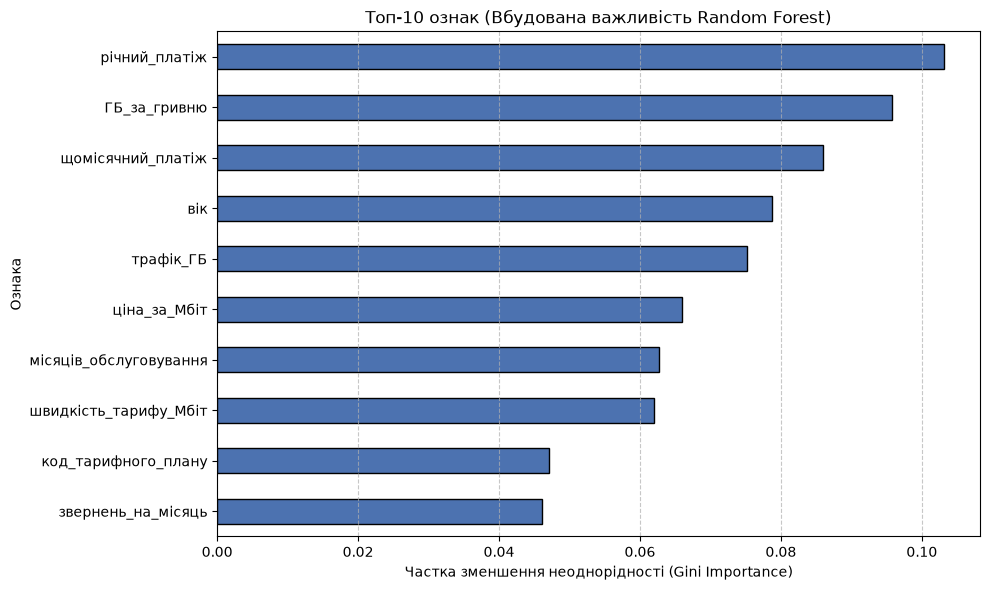

річний_платіж             0.103098
ГБ_за_гривню              0.095733
щомісячний_платіж         0.085993
вік                       0.078736
трафік_ГБ                 0.075206
ціна_за_Мбіт              0.065951
місяців_обслуговування    0.062645
швидкість_тарифу_Мбіт     0.062010
код_тарифного_плану       0.047026
звернень_на_місяць        0.046057
dtype: float64

In [30]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
out_names = model.named_steps['preprocessor'].get_feature_names_out()
rf_importances = model.named_steps['classifier'].feature_importances_
# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
imp_dict = {col: 0.0 for col in FINAL_X.columns}

for out_name, imp in zip(out_names, rf_importances):
    clean_name = out_name.split('__')[-1]
    
    for orig_col in FINAL_X.columns:
        if clean_name == orig_col or clean_name.startswith(orig_col + '_'):
            imp_dict[orig_col] += imp
            break
# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
gini_imp = pd.Series(imp_dict).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
gini_imp.tail(10).plot(kind='barh', color='#4C72B0', edgecolor='black')
plt.title('Топ-10 ознак (Вбудована важливість Random Forest)')
plt.xlabel('Частка зменшення неоднорідності (Gini Importance)')
plt.ylabel('Ознака')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

gini_imp = gini_imp.sort_values(ascending=False)
display(gini_imp.head(10))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.042075
ГБ_за_гривню,0.027429
річний_платіж,0.020646
місяців_обслуговування,0.020644
швидкість_тарифу_Мбіт,0.017783
щомісячний_платіж,0.016734
кількість_послуг,0.010361
звернень_на_місяць,0.007663
трафік_ГБ,0.006921
аварій_на_ділянці_за_квартал,0.003460


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
comparison = pd.DataFrame({
    'вбудована_важливість': gini_imp,
    'перестановочна_важливість': perm_imp
})
comparison = comparison.sort_values(by='вбудована_важливість', ascending=False)

print("=== Порівняння важливостей ===")
display(comparison.head(10))

=== Порівняння важливостей ===


,вбудована_важливість,перестановочна_важливість
річний_платіж,0.103098,0.020646
ГБ_за_гривню,0.095733,0.027429
щомісячний_платіж,0.085993,0.016734
вік,0.078736,0.042075
трафік_ГБ,0.075206,0.006921
ціна_за_Мбіт,0.065951,0.001247
місяців_обслуговування,0.062645,0.020644
швидкість_тарифу_Мбіт,0.062010,0.017783
код_тарифного_плану,0.047026,-0.006094
звернень_на_місяць,0.046057,0.007663


In [33]:
FAKE_IMPORTANT = 'трафік_ГБ'        # назва ознаки
FAKE_IMPORTANT_WHY = 'Ця числова ознака має високу кардинальність. Дерево створює безліч дрібних розбиттів на трейні, що штучно завищує її вбудовану важливість'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: трафік_ГБ


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
numeric_cols = FINAL_X.select_dtypes(include=[np.number]).columns
corr_matrix = FINAL_X[numeric_cols].corr()

print("=== Пари ознак із кореляцією |r| > 0.97 ===")
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.97:
            print(f"{corr_matrix.columns[i]} та {corr_matrix.columns[j]}: {corr_matrix.iloc[i, j]:.4f}")

=== Пари ознак із кореляцією |r| > 0.97 ===
річний_платіж та щомісячний_платіж: 0.9992


In [35]:
DUP_PAIR = ['річний_платіж', 'щомісячний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----

col_to_keep = DUP_PAIR[0]
col_to_drop = DUP_PAIR[1]

Xtr_red = Xtr.drop(columns=[col_to_drop])
Xte_red = Xte.drop(columns=[col_to_drop])
FINAL_X_red = FINAL_X.drop(columns=[col_to_drop])

model_red = make_pipe(FINAL_X_red, FINAL_CLF).fit(Xtr_red, ytr)

result_red = permutation_importance(
    model_red, Xte_red, yte, 
    scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=-1
)

idx_keep = list(Xte_red.columns).index(col_to_keep)
imp_without_pair = result_red.importances_mean[idx_keep]

print('\nбез пари:')
print('   %-28s %+.4f' % (col_to_keep, imp_without_pair))

у повній моделі:
   річний_платіж                +0.0206
   щомісячний_платіж            +0.0167

без пари:
   річний_платіж                +0.0497


In [36]:
DUP_EXPLANATION = 'річний платіж це ті самі дані й щомісячний платіж, перестановочна важливість показує їхній вплив заниженим, бо при перемішуванні однієї ознаки модель просто дістає інформацію з іншої. Лише після видалення дубля ми бачимо справжню вагомість цієї метрики'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

річний платіж це ті самі дані й щомісячний платіж, перестановочна важливість показує їхній вплив заниженим, бо при перемішуванні однієї ознаки модель просто дістає інформацію з іншої. Лише після видалення дубля ми бачимо справжню вагомість цієї метрики


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

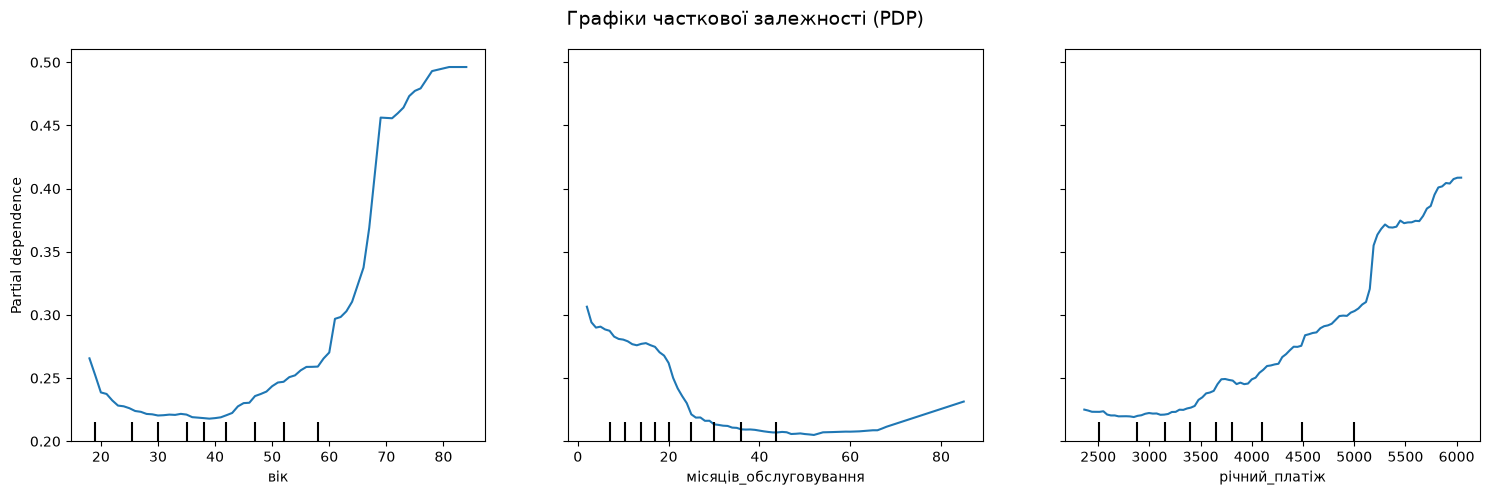

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
# PartialDependenceDisplay.from_estimator(model, Xte, features=[...], kind='average')
# Увага: ознака з пропусками дасть порожню сітку — беріть ознаки без NaN
# або будуйте PDP на підвибірці, де ця ознака заповнена.

FINAL_X = X5
Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3, stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)

top_3_num = ['вік', 'місяців_обслуговування', 'річний_платіж']

Xte_clean = Xte.dropna(subset=top_3_num)

fig, ax = plt.subplots(figsize=(15, 5))
display_pdp = PartialDependenceDisplay.from_estimator(
    model, 
    Xte_clean, 
    features=top_3_num, 
    kind='average',
    ax=ax
)
fig.suptitle('Графіки часткової залежності (PDP)', fontsize=14)
plt.tight_layout()
plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

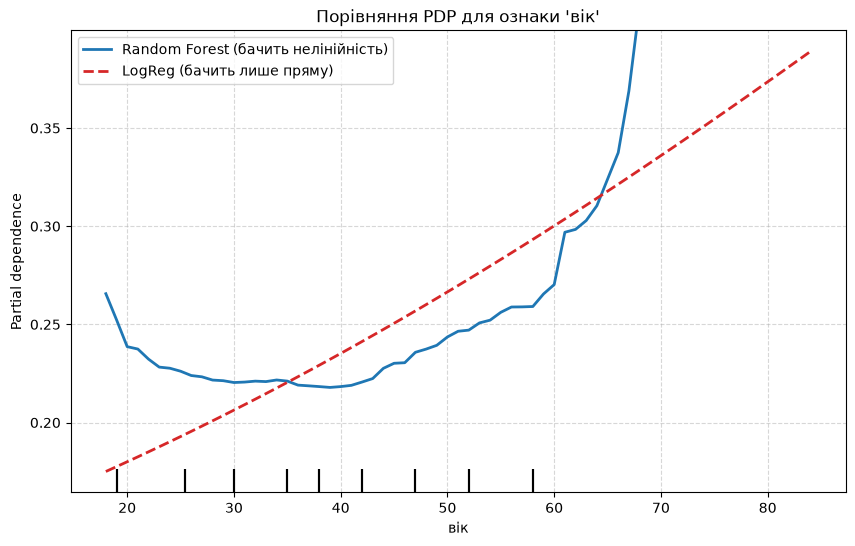

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

Xte_clean_nl = Xte.dropna(subset=[NONLINEAR_FEATURE])

fig, ax = plt.subplots(figsize=(10, 6))

display_rf = PartialDependenceDisplay.from_estimator(
    model, 
    Xte_clean_nl, 
    features=[NONLINEAR_FEATURE], 
    ax=ax, 
    line_kw={'color': '#1f77b4', 'linewidth': 2, 'label': 'Random Forest (бачить нелінійність)'}
)

PartialDependenceDisplay.from_estimator(
    model_lr, 
    Xte_clean_nl, 
    features=[NONLINEAR_FEATURE], 
    ax=display_rf.axes_, 
    line_kw={'color': '#d62728', 'linewidth': 2, 'linestyle': '--', 'label': 'LogReg (бачить лише пряму)'}
)

plt.title(f"Порівняння PDP для ознаки '{NONLINEAR_FEATURE}'")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [39]:
NONLINEAR_MEANING = 'Клієнти до 25 частіше розривають контракти, в силу частих змін у житті, вибірка 25-45 найстабільніші, 45+, а осолбливо 55+ набагато частіше розривають контракт'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'Потрібно дискретизувати вік і закодувати OHE - тоді кожна категорія буде впливати окремо на результат '         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Клієнти до 25 частіше розривають контракти, в силу частих змін у житті, вибірка 25-45 найстабільніші, 45+, а осолбливо 55+ набагато частіше розривають контракт
Потрібно дискретизувати вік і закодувати OHE - тоді кожна категорія буде впливати окремо на результат 


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
MIN_AGE = 38 
X_poly = FINAL_X.copy()
# 2) додайте ознаку «квадрат відхилення від цього значення»;
X_poly['вік_відхилення_кв'] = (X_poly['вік'] - MIN_AGE) ** 2
# 3) парне порівняння логістичної регресії з нею і без неї.
auc_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_poly = cross_val_score(make_pipe(X_poly, logreg()), X_poly, y, cv=cv, scoring='roc_auc')

m, h = paired(auc_base, auc_poly)

print('Логістична регресія (базова)  : AUC %.3f' % auc_base.mean())
print('Логістична регресія (парабола): AUC %.3f' % auc_poly.mean())
print('приріст від квадратичної ознаки: %+0.4f ± %.4f   %s' 
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

Логістична регресія (базова)  : AUC 0.816
Логістична регресія (парабола): AUC 0.842
приріст від квадратичної ознаки: +0.0261 ± 0.0079   значуще


In [41]:
QUAD_GAIN = 0.0261     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0261


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

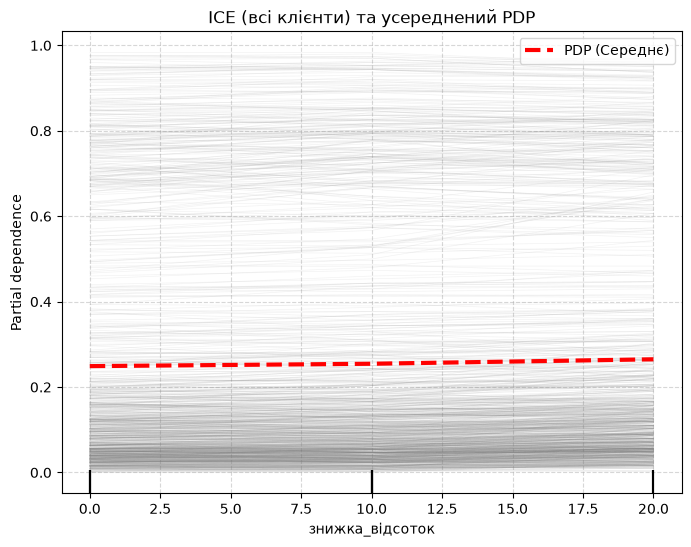

In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(figsize=(8, 6))

PartialDependenceDisplay.from_estimator(
    model, 
    FINAL_X, 
    features=['знижка_відсоток'], 
    kind='both', 
    ice_lines_kw={'color': 'gray', 'alpha': 0.1, 'linewidth': 0.5},
    pd_line_kw={'color': 'red', 'linewidth': 3, 'label': 'PDP (Середнє)'},
    ax=ax
)
ax.set_title("ICE (всі клієнти) та усереднений PDP")
ax.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

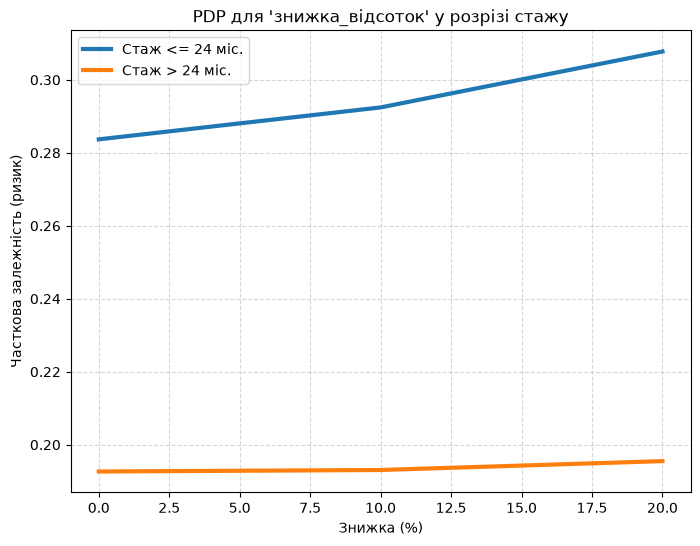

In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
mask_new = FINAL_X['місяців_обслуговування'] <= 24
mask_old = FINAL_X['місяців_обслуговування'] > 24

pdp_new = partial_dependence(model, FINAL_X[mask_new], ['знижка_відсоток'], kind='average')
pdp_old = partial_dependence(model, FINAL_X[mask_old], ['знижка_відсоток'], kind='average')

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(pdp_new['grid_values'][0], pdp_new['average'][0], color='#1f77b4', linewidth=3, label='Стаж <= 24 міс.')
ax.plot(pdp_old['grid_values'][0], pdp_old['average'][0], color='#ff7f0e', linewidth=3, label='Стаж > 24 міс.')

ax.set_title("PDP для 'знижка_відсоток' у розрізі стажу")
ax.set_xlabel("Знижка (%)")
ax.set_ylabel("Часткова залежність (ризик)")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
df_check = FINAL_X[['знижка_відсоток', 'місяців_обслуговування']].copy()
df_check['відтік'] = y

df_check['група_стажу'] = np.where(df_check['місяців_обслуговування'] <= 24, '1. до 24 міс.', '2. понад 24 міс.')

pivot_discount = df_check.groupby(['група_стажу', 'знижка_відсоток'])['відтік'].agg(
    частка_відтоку='mean',
    розмір_групи='count'
).reset_index()

display(pivot_discount)

,група_стажу,знижка_відсоток,частка_відтоку,розмір_групи
0,1. до 24 міс.,0.0,0.258741,286
1,1. до 24 міс.,10.0,0.329502,261
2,1. до 24 міс.,20.0,0.372449,196
3,2. понад 24 міс.,0.0,0.192513,187
4,2. понад 24 міс.,10.0,0.198529,136
5,2. понад 24 міс.,20.0,0.082090,134


In [45]:
INTERACTION_FOUND = 'Для нових клієнтів знижка не дає гарантій утримання, а навпаки, проте для лояльних клієнтів збільшення знижки суттєво зменшує ймовірність розірвання контракту'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'Не потрібно пропонувати знижку новим клієнтам - швидше за все вони всеодно підуть, а старим клієнтам навпаки - пропонувати знижку'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Для нових клієнтів знижка не дає гарантій утримання, а навпаки, проте для лояльних клієнтів збільшення знижки суттєво зменшує ймовірність розірвання контракту
Не потрібно пропонувати знижку новим клієнтам - швидше за все вони всеодно підуть, а старим клієнтам навпаки - пропонувати знижку


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['preprocessor']
clf = model.named_steps['classifier']

Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 38)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

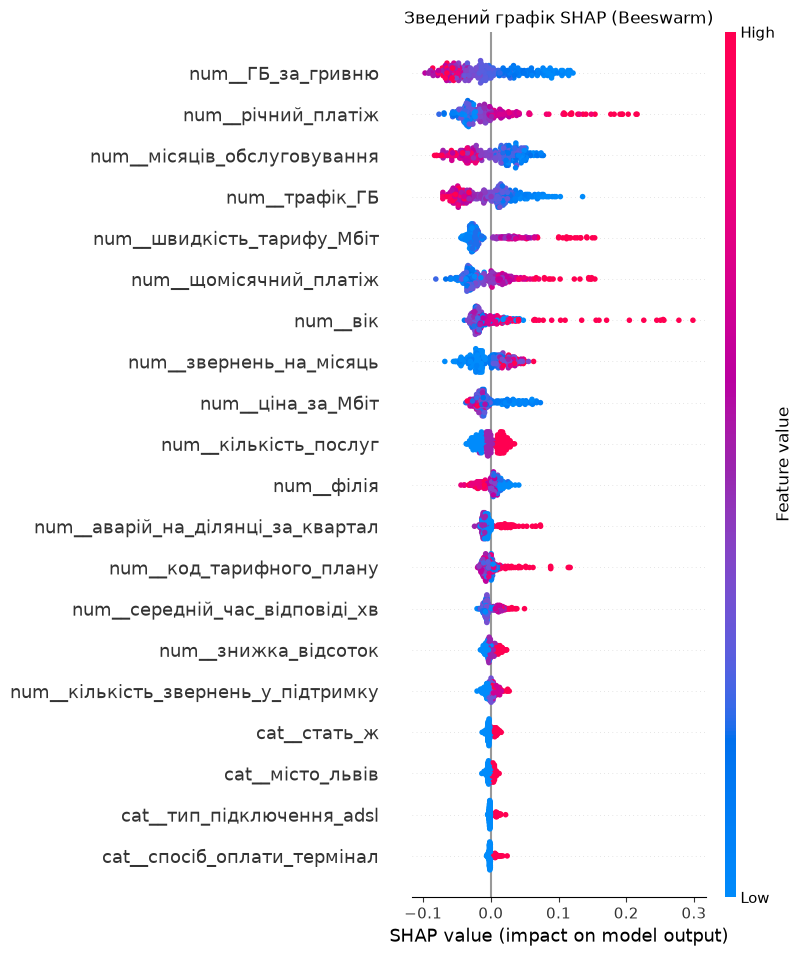

In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, show=False)
plt.title("Зведений графік SHAP (Beeswarm)")
plt.show()

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
client_shap_values = sv1[idx]
top3_indices = np.argsort(np.abs(client_shap_values))[-3:][::-1]

print("\n--- Технічне виведення для аналітика ---")
for i in top3_indices:
    feat = feat_names[i]
    val = Xte_t[idx, i]
    contrib = client_shap_values[i]
    direction = "підвищує ризик" if contrib > 0 else "знижує ризик"
    print(f"Ознака: {feat:<25} | Внесок: {contrib:+.3f} ({direction}) | Фактичне значення: {val}")

ризик клієнта: 0.923

--- Технічне виведення для аналітика ---
Ознака: num__річний_платіж        | Внесок: +0.182 (підвищує ризик) | Фактичне значення: 3.459907773294462
Ознака: num__швидкість_тарифу_Мбіт | Внесок: +0.133 (підвищує ризик) | Фактичне значення: 2.591465476895918
Ознака: num__щомісячний_платіж    | Внесок: +0.123 (підвищує ризик) | Фактичне значення: 3.731842355248044


In [49]:
EXPLANATION_FOR_MANAGER = 'Клієнт відчуває, що платить в рік/місяць забагато, також його не влаштовує швидкість інтернету'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнт відчуває, що платить в рік/місяць забагато, також його не влаштовує швидкість інтернету


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'кількість_звернень_у_підтримку'
SHAP_NOT_CAUSAL_WHY = 'Кількість звернень в підтримку це симтом, а не першопричина. Стараючись зменшити кількість звернень (наприклад відмовившись від служби підтримки) ми навпаки приближимо клієнта до розірвання контракту'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

кількість_звернень_у_підтримку — Кількість звернень в підтримку це симтом, а не першопричина. Стараючись зменшити кількість звернень (наприклад відмовившись від служби підтримки) ми навпаки приближимо клієнта до розірвання контракту


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",трафік_ГБ,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",річний_платіж + щомісячний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",кількість_звернень_у_підтримку,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'Плутанина бізнес-проблеми з артефактом збору даних: SHAP може вказати на високий ризик у філії Ф-06, але це відображає лише специфіку вивантаження CSV-файлу (наприклад різні періоди), а не реальну погану роботу персоналу'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Плутанина бізнес-проблеми з артефактом збору даних: SHAP може вказати на високий ризик у філії Ф-06, але це відображає лише специфіку вивантаження CSV-файлу (наприклад різні періоди), а не реальну погану роботу персоналу


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100

probas = model.predict_proba(Xte)[:, 1]
results = pd.DataFrame({'proba': probas, 'true': yte})
top_100 = results.sort_values('proba', ascending=False).head(TOP_N)

top_churn_rate = top_100['true'].mean()
churned_in_top = top_100['true'].sum()

overall_churn_rate = yte.mean()
expected_random = overall_churn_rate * TOP_N

lift = top_churn_rate / overall_churn_rate

print(f"Справді пішли з ТОП-{TOP_N}: {churned_in_top} клієнтів")
print(f"Знайшли б навмання (очікувано): {expected_random:.1f} клієнтів")
print(f"Lift: {lift:.3f}")

Справді пішли з ТОП-100: 56 клієнтів
Знайшли б навмання (очікувано): 25.6 клієнтів
Lift: 2.191


In [54]:
LIFT_MEANING = 'lift показує у скільки разів модель точніше знаходить тих, хто розірве контракт, аніж випадково'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

lift показує у скільки разів модель точніше знаходить тих, хто розірве контракт, аніж випадково


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_08.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [57]:
REPORT = '''
1. Обрав ROC-AUC, оскільки вона оцінює здатність моделі розрізняти класи незалежно від порогу класифікації. Частка відтоку — 25,6%, тому модель «ніхто не піде» мала б точність 74,4%
2. З моделі було вилучено стовпець id_клієнта, оскільки він є лише ідентифікатором, код_причини_закриття та дата_розірвання, оскільки ці дані стають відомими лише після відтоку клієнта. Також було вилучено індекс_лояльності_CRM та оцінка_ризику_менеджером через ризик витоку інформації з майбутнього, а дата_підключення — через виявлений артефакт збору даних
3. Чесний результат — AUC = 0,819 ± 0,028. Різниця між моделями на 0,004 не є переконливою, оскільки вона значно менша за розкид результатів
4. Так, виявлено зв'язок між датою підключення та джерелом даних: AUC = 0,786. Це означає, що модель може розпізнавати особливості періоду збору даних. В іншій філії її результати можуть бути менш надійними.
5. Початкове конструювання трьох нових ознак дало приріст AUC −0,0032 ± 0,0030. Складніші моделі дали лише +0,0022 ± 0,0126 (Випадковий ліс) та +0,0017 ± 0,0134 (гістограмний бустинг). Їхнє навчання тривало 3,5 та 4,8 с проти 0,6 с для логістичної регресії. Натомість квадратична ознака віку дала значущий приріст +0,0261 ± 0,0079. Отже, вдало сконструйовані ознаки можуть бути кориснішими за ускладнення моделі.
6. трафік_ГБ. Дерева можуть переоцінювати ознаки з великою кількістю унікальних значень, оскільки вони дають більше можливостей для розбиття даних
7. річний_платіж і щомісячний_платіж мають кореляцію 0,9992. Через дублювання інформації перестановочна важливість кожної ознаки занижується. Після вилучення однієї з них важливість річного платежу зросла з 0,0206 до 0,0497
8. Вік. Ризик відтоку вищий серед молодших клієнтів, найнижчий приблизно біля 38 років, а після 45–55 років знову зростає. Логістична регресія без додаткових ознак не змогла б самостійно відобразити таку нелінійність
9. Для ознаки знижка_відсоток. PDP приховав різницю між групами клієнтів. ICE показав різноспрямований вплив: для нових клієнтів збільшення знижки пов'язане зі зростанням відтоку, а для клієнтів зі стажем понад 24 місяці — зі зменшенням
10. кількість_звернень_у_підтримку. Це може бути наслідком проблем клієнта, а не їхньою причиною. Зменшення кількості звернень саме по собі не усуне проблем і може навіть погіршити ситуацію
11. Модель можна використовувати для пріоритизації дзвінків, але після додаткової перевірки на інших даних. Серед 100 клієнтів із найвищим ризиком справді пішли 56, тоді як навмання очікувалося б 25,6. Lift = 2,191. Застереження: модель не доводить, що запропонована знижка справді допоможе втримати клієнта

Декларація про використання ШІ:
Використовував Gemini для генерації коду, перевіряв на відповідність цільовій задачі та дієздатність 
'''
print(REPORT)


1. Обрав ROC-AUC, оскільки вона оцінює здатність моделі розрізняти класи незалежно від порогу класифікації. Частка відтоку — 25,6%, тому модель «ніхто не піде» мала б точність 74,4%
2. З моделі було вилучено стовпець id_клієнта, оскільки він є лише ідентифікатором, код_причини_закриття та дата_розірвання, оскільки ці дані стають відомими лише після відтоку клієнта. Також було вилучено індекс_лояльності_CRM та оцінка_ризику_менеджером через ризик витоку інформації з майбутнього, а дата_підключення — через виявлений артефакт збору даних
3. Чесний результат — AUC = 0,819 ± 0,028. Різниця між моделями на 0,004 не є переконливою, оскільки вона значно менша за розкид результатів
4. Так, виявлено зв'язок між датою підключення та джерелом даних: AUC = 0,786. Це означає, що модель може розпізнавати особливості періоду збору даних. В іншій філії її результати можуть бути менш надійними.
5. Початкове конструювання трьох нових ознак дало приріст AUC −0,0032 ± 0,0030. Складніші моделі дали лише +0

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.